# C1 sample run: FoodSeg103 segmenter (P3)

C1 takes a top-down meal photo and returns a FoodSeg103 label for every pixel, plus the share of the food area each label covers. C3 turns those shares into grams (`grams_i = total_mass * area_i`).

* **Model:** Mask2Former with a Swin-T backbone, trained on FoodSeg103 (104 classes = background + 103 foods), used frozen. Weights: `mericberktas/foodseg-models` on Hugging Face, pinned to one commit (`plate_check.c1_segmentation.HF_REVISION`).
* **Input:** RGB photo, resized to 512 x 512 for the model; the mask comes back at the photo's own size.
* **Output:** `SegmentationResult(mask, pixel_counts, area_fractions)`.

Runs on Colab (GPU optional) or locally from the repo root.

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    !git clone -q -b c1-segmentation https://github.com/MysteryCoder456/PlateCheck.git
    %cd PlateCheck
    !pip -q install transformers huggingface_hub safetensors scipy
else:
    # running from notebooks/ inside the repo
    if os.path.basename(os.getcwd()) == 'notebooks':
        os.chdir('..')
sys.path.insert(0, 'src')
print(os.getcwd())

PlateCheck


## 1. Load the frozen checkpoint
Downloads ~190 MB the first time. Set `PLATECHECK_C1_WEIGHTS` to reuse a local copy.

In [2]:
from pathlib import Path
import numpy as np, torch
from PIL import Image
from plate_check import c1_segmentation as c1

weights = os.environ.get('PLATECHECK_C1_WEIGHTS')
model_dir = Path(weights) if weights else c1.download_weights('models')
seg = c1.FoodSegmenter(model_dir)
print('device:', seg.device, '| params (M):', round(sum(p.numel() for p in seg.model.parameters()) / 1e6, 1))
print('trainable params:', sum(p.numel() for p in seg.model.parameters() if p.requires_grad))

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

device: cpu | params (M): 47.4
trainable params: 0


## 2. Sample Nutrition5k dishes
Eight dishes from the official **RGB test split**, overhead RealSense `rgb.png`, plus their ingredient weights from `dish_metadata_cafe1.csv` (public bucket, CC BY 4.0).

In [3]:
import csv, urllib.request
BUCKET = 'https://storage.googleapis.com/nutrition5k_dataset/nutrition5k_dataset'
DATA = Path(os.environ.get('PLATECHECK_N5K_DIR', 'data/nutrition5k'))
DISHES = ['dish_1558549605', 'dish_1558639818', 'dish_1561663580', 'dish_1565035746',
          'dish_1565898402', 'dish_1566328724', 'dish_1566838351', 'dish_1567107839']

def fetch(url, path):
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, path)
    return path

meta_path = fetch(f'{BUCKET}/metadata/dish_metadata_cafe1.csv', DATA / 'metadata/dish_metadata_cafe1.csv')
meta = {}
for row in csv.reader(open(meta_path)):
    if row[0] in DISHES:
        ingr = row[6:]
        meta[row[0]] = {
            'kcal': float(row[1]), 'mass_g': float(row[2]),
            'ingredients': [(ingr[i + 1], float(ingr[i + 2])) for i in range(0, len(ingr) - 6, 7)],
        }
images = {d: Image.open(fetch(f'{BUCKET}/imagery/realsense_overhead/{d}/rgb.png', DATA / f'imagery/{d}/rgb.png')).convert('RGB')
          for d in DISHES}
print({d: im.size for d, im in images.items()})

{'dish_1558549605': (640, 480), 'dish_1558639818': (640, 480), 'dish_1561663580': (640, 480), 'dish_1565035746': (640, 480), 'dish_1565898402': (640, 480), 'dish_1566328724': (640, 480), 'dish_1566838351': (640, 480), 'dish_1567107839': (640, 480)}


## 3. Run C1

In [4]:
import time
results, times = {}, []
for d, im in images.items():
    t0 = time.time()
    results[d] = seg.segment(im)
    times.append(time.time() - t0)
print(f'{np.mean(times):.2f} s / image on {seg.device}')

1.33 s / image on cpu


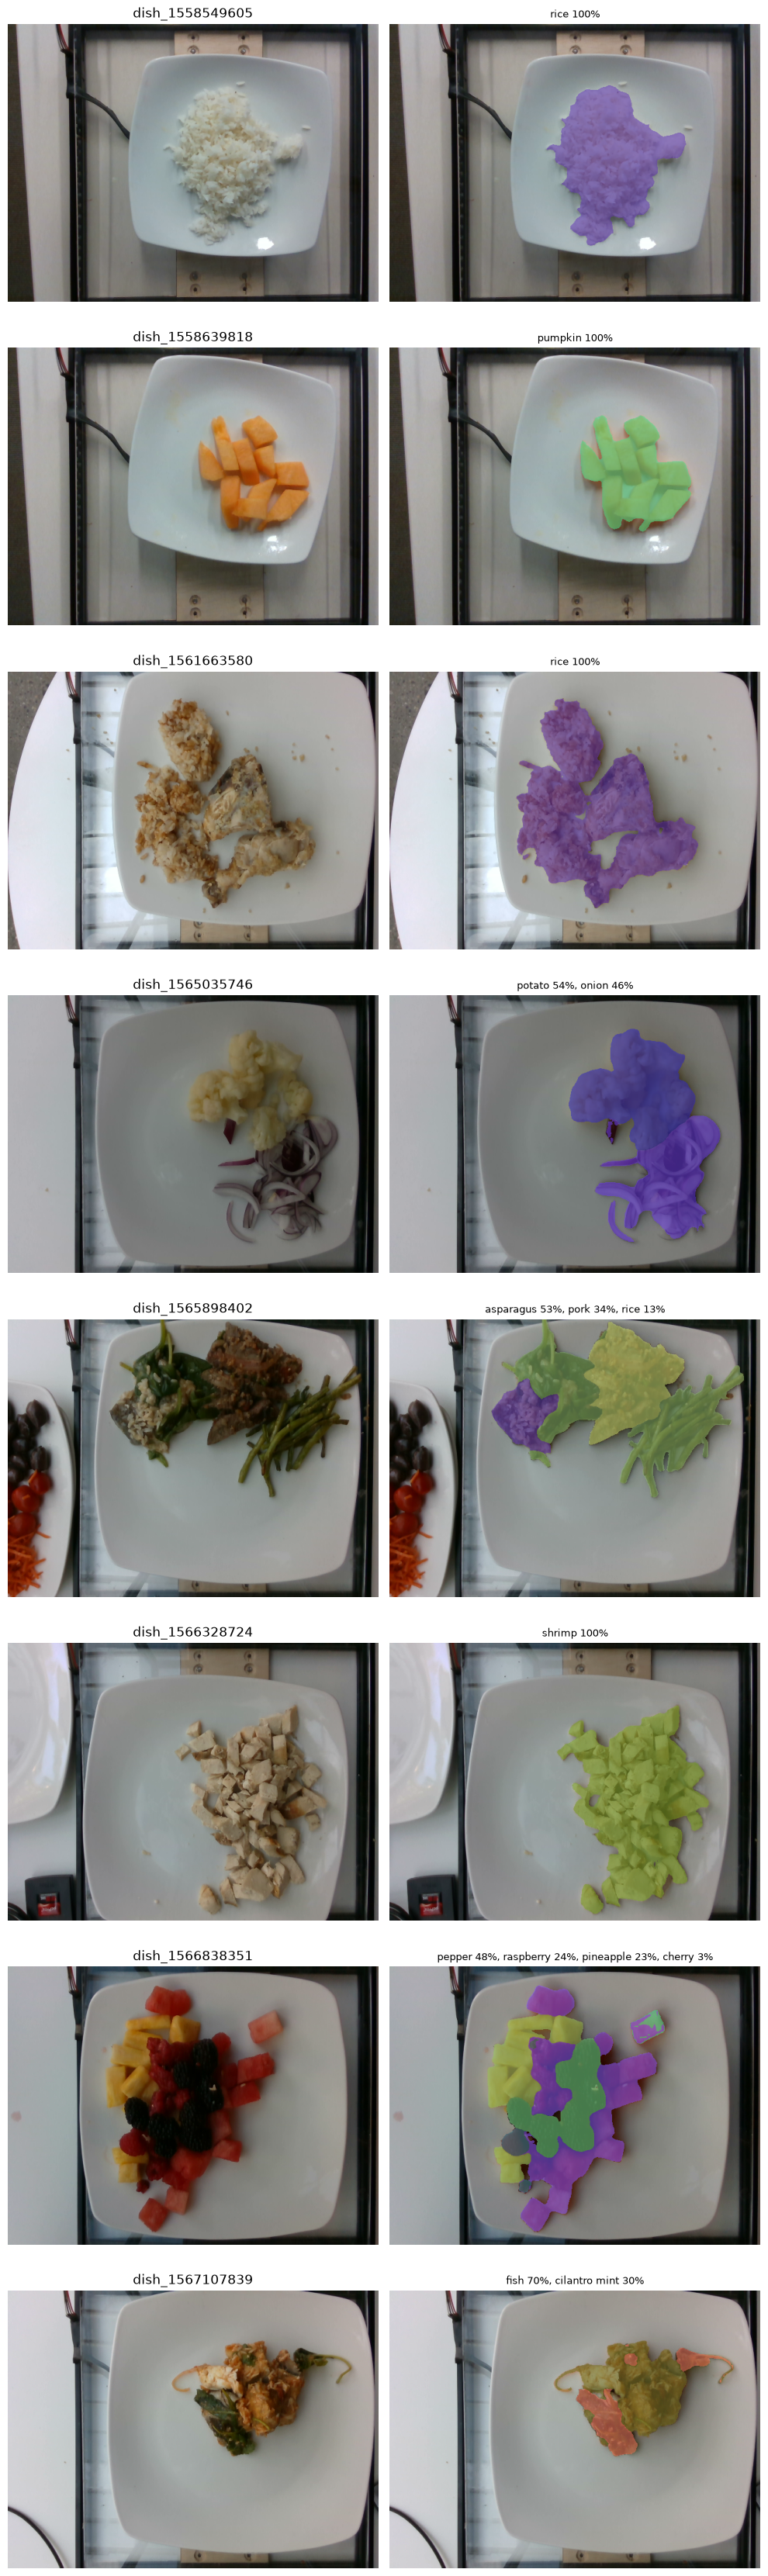

In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(len(DISHES), 2, figsize=(10, 4.2 * len(DISHES)))
for (d, res), (ax0, ax1) in zip(results.items(), axes):
    ax0.imshow(images[d]); ax0.set_title(d); ax0.axis('off')
    ax1.imshow(c1.overlay(images[d], res.mask)); ax1.axis('off')
    top = ', '.join(f'{n} {f:.0%}' for n, f in res.items()[:4])
    ax1.set_title(top, fontsize=9)
plt.tight_layout(); plt.show()

## 4. Predicted items vs. Nutrition5k ingredients
Nutrition5k lists every ingredient by weight (including oil, salt and sauces nobody can see), so this is a qualitative check, not a score.

In [6]:
for d, res in results.items():
    gt = sorted(meta[d]['ingredients'], key=lambda x: -x[1])
    gt_str = ', '.join(f'{n} {g:.0f}g' for n, g in gt if g >= 0.05 * meta[d]['mass_g'])
    pred_str = ', '.join(f'{n} {f:.0%}' for n, f in res.items())
    print(f"{d}  total {meta[d]['mass_g']:.0f} g\n  Nutrition5k (>=5% mass): {gt_str}\n  C1 area shares:          {pred_str}\n")

dish_1558549605  total 75 g
  Nutrition5k (>=5% mass): white rice 75g
  C1 area shares:          rice 100%

dish_1558639818  total 59 g
  Nutrition5k (>=5% mass): cantaloupe 59g
  C1 area shares:          pumpkin 100%

dish_1561663580  total 307 g
  Nutrition5k (>=5% mass): chicken 154g, brown rice 127g, carrot 15g
  C1 area shares:          rice 100%

dish_1565035746  total 149 g
  Nutrition5k (>=5% mass): cauliflower 110g, onions 39g
  C1 area shares:          potato 54%, onion 46%

dish_1565898402  total 229 g
  Nutrition5k (>=5% mass): beef 78g, salmon 73g, green beans 26g, brown rice 15g
  C1 area shares:          asparagus 53%, pork 34%, rice 13%

dish_1566328724  total 167 g
  Nutrition5k (>=5% mass): chicken 167g
  C1 area shares:          shrimp 100%

dish_1566838351  total 417 g
  Nutrition5k (>=5% mass): pineapple 145g, watermelon 139g, berries 133g
  C1 area shares:          pepper 48%, raspberry 24%, pineapple 23%, cherry 3%, pumpkin 1%

dish_1567107839  total 156 g
  Nutr

## 5. What C1 hands to C3
Area shares over food pixels (background excluded). With C2's total mass, C3 computes grams per item.

In [7]:
import json
d = DISHES[2]
res = results[d]
handoff = {'dish': d, 'area_fractions': {k: round(v, 4) for k, v in res.items()}}
print(json.dumps(handoff, indent=2))
# Oracle-mass example (what the proposal's C3 diagnostic uses): true total mass split by area
print({k: round(v * meta[d]['mass_g'], 1) for k, v in res.items()})

{
  "dish": "dish_1561663580",
  "area_fractions": {
    "rice": 1.0
  }
}
{'rice': 307.0}


## 6. C1 check on FoodSeg103 validation images
The checkpoint's config only names its outputs `LABEL_0..LABEL_103`, and its food indices turned out to be rotated by 13 (FoodSeg103 class *g* comes out as *(g + 13) mod 104*). `c1_segmentation.CHECKPOINT_TO_FOODSEG` undoes that. The rotation was spotted on validation rows 0-105 and is checked here on rows 106-211, which were not used to find it. Without the fix the same check gives pixel accuracy 0.52 and food mIoU 0.001.

Masks come from the Hugging Face dataset viewer (`EduardoPacheco/FoodSeg103`), which re-encodes them lossily, so each pixel is snapped to the nearest class listed for that image. mIoU is over classes present in each image's ground truth, pooled over the subset; it is not the official full-validation number.

In [8]:
import json, urllib.request
from concurrent.futures import ThreadPoolExecutor
VAL = Path(os.environ.get('PLATECHECK_VAL_DIR', 'data/foodseg103_val'))
API = 'https://datasets-server.huggingface.co/rows?dataset=EduardoPacheco/FoodSeg103&config=default&split=validation'
rows = []
for off, n in ((106, 100), (206, 6)):
    rows += [r['row'] for r in json.load(urllib.request.urlopen(f'{API}&offset={off}&length={n}'))['rows']]
def get(row):
    for key, ext in (('image', '.jpg'), ('label', '.png')):
        fetch(row[key]['src'], VAL / f"{row['id']}_{key}{ext}")
with ThreadPoolExecutor(8) as ex:
    list(ex.map(get, rows))
print(len(rows), 'held-out validation images')

106 held-out validation images


In [9]:
def snap(gt, classes):
    classes = np.array(sorted(classes))
    return classes[np.abs(gt[..., None].astype(int) - classes[None, None, :]).argmin(-1)]

conf = np.zeros((104, 104), dtype=np.int64)  # ground truth x prediction
t0 = time.time()
for row in rows:
    img = Image.open(VAL / f"{row['id']}_image.jpg").convert('RGB')
    gt = snap(np.array(Image.open(VAL / f"{row['id']}_label.png").convert('L')), row['classes_on_image'])
    pred = seg.predict_mask(img)  # raw model output after the label fix, no small-region cleanup
    conf += np.bincount(gt.ravel() * 104 + pred.ravel(), minlength=104 * 104).reshape(104, 104)
inter = np.diag(conf); union = conf.sum(0) + conf.sum(1) - inter
present = conf.sum(1) > 0; food = present.copy(); food[0] = False
print(f'{len(rows)} images, {time.time() - t0:.0f} s')
print(f'pixel accuracy      {inter.sum() / conf.sum():.3f}')
print(f'mIoU (incl. bg)     {(inter[present] / union[present]).mean():.3f}')
print(f'food-class mIoU     {(inter[food] / union[food]).mean():.3f}  over {food.sum()} classes')
iou = {c1.FOODSEG103_LABELS[c]: inter[c] / union[c] for c in np.nonzero(food)[0] if conf[c].sum() > 20000}
best = sorted(iou.items(), key=lambda kv: -kv[1])
print('best :', ', '.join(f'{n} {v:.2f}' for n, v in best[:6]))
print('worst:', ', '.join(f'{n} {v:.2f}' for n, v in best[-6:]))

106 images, 130 s
pixel accuracy      0.764
mIoU (incl. bg)     0.303
food-class mIoU     0.294  over 71 classes
best : coffee 0.94, noodles 0.93, corn 0.91, French beans 0.86, strawberry 0.84, orange 0.83
worst: pasta 0.00, rape 0.00, pumpkin 0.00, white radish 0.00, white button mushroom 0.00, other ingredients 0.00


## Notes for the progress report
* C1 runs frozen end to end: photo -> 104-class mask -> area shares that C3 can multiply by C2's mass.
* Known limits: (1) the checkpoint confuses many of FoodSeg103's 103 classes and merges touching items (e.g. chicken on rice); (2) class 91 "cabbage" collides with background because of the label rotation; (3) Nutrition5k's overhead RealSense photos are lower quality and differently lit than FoodSeg103, so expect worse labels there than on the validation numbers above.
* Next: map FoodSeg103 labels to USDA FoodData Central rows for C3, and measure C3 with the oracle mass (true total mass split by C1's area shares) as the proposal describes.